In [47]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import ListedColormap
from scipy.stats import ks_2samp, anderson_ksamp

import warnings
import tqdm

## Reading samples

In [48]:
harps = pd.read_csv('harps_final_for_feh.csv')
apogee = pd.read_csv('apogee_final_for_feh.csv')
galah = pd.read_csv('galah_final_for_feh.csv')

print (f'harps contains {len(harps)} stars')
print (f'apogee contains {len(apogee)} stars')    
print (f'galah contains {len(galah)} stars')


harps contains 798 stars
apogee contains 45726 stars
galah contains 71591 stars


In [49]:
def distribution_test_trio(df1, df2, df3, features, labels=("df1", "df2", "df3")):
    """
    Compare distributions using KS and AD tests across three datasets.

    Parameters:
        df1, df2, df3: DataFrames to compare
        features: list of feature names to test
        labels: tuple of labels for the dataframes (used in column names)

    Returns:
        pandas DataFrame with KS and AD p-values for each feature and pair
    """
    results = []

    for feature in features:
        try:
            # Extract valid (non-NaN) numeric values
            x1 = pd.to_numeric(df1[feature], errors='coerce').dropna()
            x2 = pd.to_numeric(df2[feature], errors='coerce').dropna()
            x3 = pd.to_numeric(df3[feature], errors='coerce').dropna()

            # Apply tests if all groups have data
            if len(x1) >= 10 and len(x2) >= 10:
                ks_12 = ks_2samp(x1, x2).pvalue
                try:
                    ad_12 = anderson_ksamp([x1, x2]).pvalue
                except Exception:
                    ad_12 = np.nan
            else:
                ks_12 = ad_12 = np.nan

            if len(x1) >= 10 and len(x3) >= 10:
                ks_13 = ks_2samp(x1, x3).pvalue
                try:
                    ad_13 = anderson_ksamp([x1, x3]).pvalue
                except Exception:
                    ad_13 = np.nan
            else:
                ks_13 = ad_13 = np.nan

            if len(x2) >= 10 and len(x3) >= 10:
                ks_23 = ks_2samp(x2, x3).pvalue
                try:
                    ad_23 = anderson_ksamp([x2, x3]).pvalue
                except Exception:
                    ad_23 = np.nan
            else:
                ks_23 = ad_23 = np.nan

            results.append({
                'feature': feature,
                f'KS_{labels[0]}_{labels[1]}': ks_12,
                #f'AD_{labels[0]}_{labels[1]}': ad_12,
                f'KS_{labels[0]}_{labels[2]}': ks_13,
                #f'AD_{labels[0]}_{labels[2]}': ad_13,
                f'KS_{labels[1]}_{labels[2]}': ks_23,
                #f'AD_{labels[1]}_{labels[2]}': ad_23,
            })

        except Exception as e:
            print(f"Error processing {feature}: {e}")
            continue

    df = pd.DataFrame(results)
    for col in df.columns:
        if col != 'feature' and df[col].dtype == float:
            df[col] = df[col].map(lambda x: f"{x:.3f}" if pd.notna(x) else "")
    return df


In [50]:
features_to_test = harps.columns  # or your ML feature list
results_df = distribution_test_trio(harps, apogee, galah, features_to_test, labels=('HARPS', 'APOGEE', 'GALAH'))
results_df


/tmp/ipykernel_20521/3184350185.py:26: UserWarning: p-value floored: true value smaller than 0.001. Consider specifying `method` (e.g. `method=stats.PermutationMethod()`.)
  ad_12 = anderson_ksamp([x1, x2]).pvalue
/tmp/ipykernel_20521/3184350185.py:35: UserWarning: p-value floored: true value smaller than 0.001. Consider specifying `method` (e.g. `method=stats.PermutationMethod()`.)
  ad_13 = anderson_ksamp([x1, x3]).pvalue
/tmp/ipykernel_20521/3184350185.py:44: UserWarning: p-value floored: true value smaller than 0.001. Consider specifying `method` (e.g. `method=stats.PermutationMethod()`.)
  ad_23 = anderson_ksamp([x2, x3]).pvalue


,feature,KS_HARPS_APOGEE,KS_HARPS_GALAH,KS_APOGEE_GALAH
0,zmax,0.000,0.000,0.000
1,rperi,0.000,0.010,0.000
2,P_gal,0.000,0.000,0.000
3,VW_lsr,0.000,0.000,0.000
4,eccentricity,0.000,0.000,0.000
5,rapo,0.000,0.000,0.000
6,V_lsr,0.000,0.000,0.000
7,abs_W_lsr,0.000,0.063,0.000
8,UW_lsr,0.000,0.026,0.000
9,fe_h,0.000,0.000,0.000


In [51]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import warnings

color_list = ["#1f77b4",  # blue
              "#ff7f0e",  # orange
              "#2ca02c"]  # green

cmap_custom = ListedColormap(color_list)

def plot_distribution_trio(df1, df2, df3, feature, labels=("df1", "df2", "df3"), hue="set", palette=color_list):
    # Add source labels
    df1_copy = df1.copy()
    df1_copy[hue] = labels[0]
    df2_copy = df2.copy()
    df2_copy[hue] = labels[1]
    df3_copy = df3.copy()
    df3_copy[hue] = labels[2]

    # Concatenate all
    data_df = pd.concat([df1_copy, df2_copy, df3_copy], ignore_index=True)

    # Replace infs and drop non-numeric/missing
    data_df.replace([np.inf, -np.inf], np.nan, inplace=True)
    data_df = data_df[pd.to_numeric(data_df[feature], errors='coerce').notna()]
    data_df[feature] = data_df[feature].astype(float)

    # Begin plotting
    f, axes = plt.subplots(1, 2, figsize=(16, 6))

    # Histogram
    for i, s in enumerate(data_df[hue].unique()):
        selection = data_df.loc[data_df[hue] == s, feature]
        if len(selection) < 10:
            continue

        q_025, q_975 = np.percentile(selection, [2.5, 97.5])
        selection_filtered = selection[(selection >= q_025) & (selection <= q_975)]

        with warnings.catch_warnings():
            warnings.simplefilter("ignore", category=FutureWarning)
            sns.histplot(selection_filtered, color=palette[i], ax=axes[0], label=s, kde=False)

    # Boxplot
    sns.boxplot(x=hue, y=feature, data=data_df, palette=palette, ax=axes[1])

    # Titles and legends
    axes[0].set_title(f"[2.5%-97.5%] Distribution of {feature}")
    axes[1].set_title(f"Boxplot of {feature}")
    axes[0].legend()
    plt.tight_layout()
    plt.show()


/tmp/ipykernel_20521/958559016.py:48: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x=hue, y=feature, data=data_df, palette=palette, ax=axes[1])


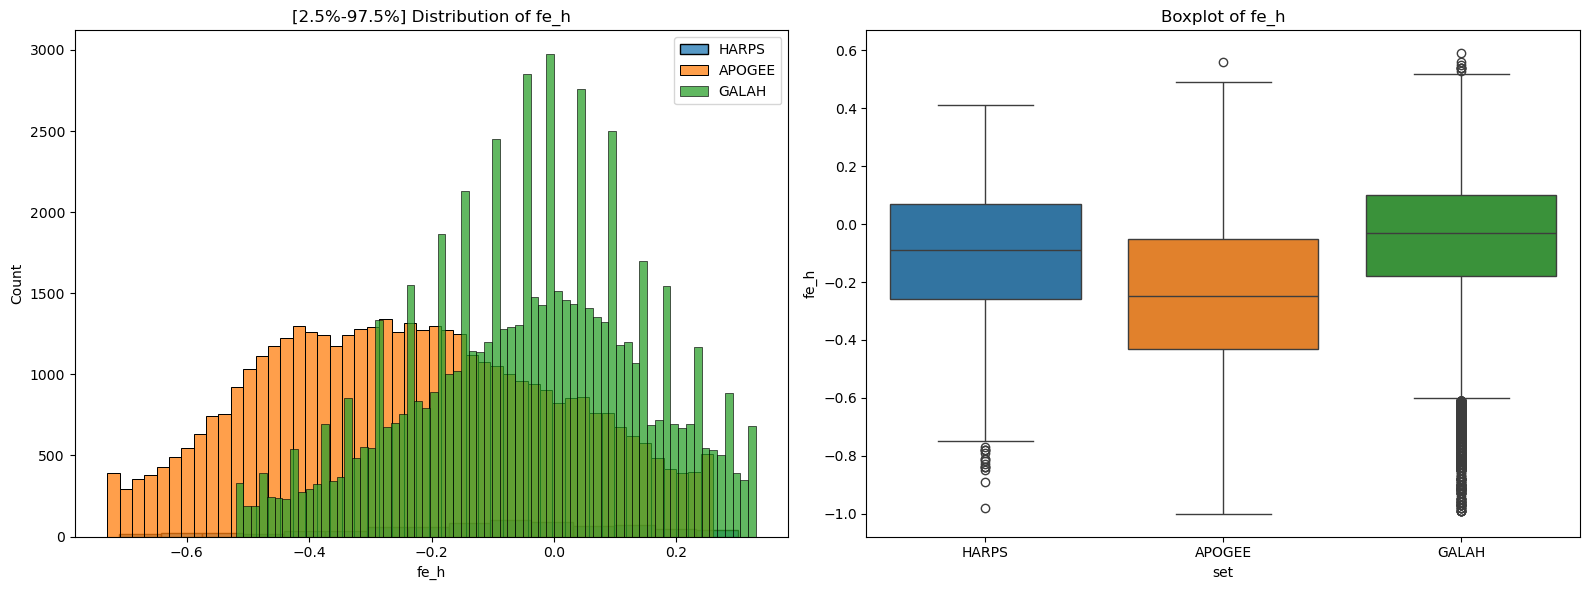

In [52]:
#for feature in cols_for_ml:
#    print(feature)
#    plot_distribution_trio(harps_combined, apogee_renamed, galah_renamed, feature=feature, labels=("HARPS", "APOGEE", "GALAH"))

# Use appropriate renamings if not done already
plot_distribution_trio(harps, apogee, galah, feature='fe_h', labels=("HARPS", "APOGEE", "GALAH"))
